# Jour 24 — IA enseignement supérieur
## Déploiement de l'agent d'admission : Batch, Real-Time, Streaming, Edge
Objectif : comprendre et **simuler** les principales stratégies de déploiement d'un agent IA, puis surveiller sa performance (MLOps).

> Les latences réseau/LLM, le taux d'échec et la remise batch sont **simulés** (paramètres dans `edudeploy/modes.py`).

In [1]:
import json, matplotlib.pyplot as plt
from edudeploy import modes, drift
from edudeploy.recommend import recommander
PARAMS = modes.PARAMS
print({k: PARAMS[k] for k in ('llm_ms','rtt_ms','p_echec_cloud','remise_batch','workers')})

{'llm_ms': (900, 2200), 'rtt_ms': (60, 140), 'p_echec_cloud': 0.03, 'remise_batch': 0.5, 'workers': {'realtime': 4, 'batch': 16, 'streaming': 8, 'edge': 1}}


## 1. Même agent, mêmes règles, 4 modes
Le scoring (règles du Jour 23, seuil HITL = 70) est identique ; seul le mode d'exécution change.

In [2]:
dossiers = modes.generer_dossiers(2000)
resultats = modes.comparer(dossiers)
import pandas as pd
df = pd.DataFrame({m: v['resume'] for m, v in resultats.items()}).T
df[['n','taux_succes_pct','latence_traitement_p95_ms','delai_resultat_moyen_s','cout_1000_dossiers_usd','donnees_quittent_appareil','hors_ligne','analyse_llm']]

,n,taux_succes_pct,latence_traitement_p95_ms,delai_resultat_moyen_s,cout_1000_dossiers_usd,donnees_quittent_appareil,hors_ligne,analyse_llm
real-time,2000,99.95,2287.0,1.718,0.0591,True,False,True
batch,2000,99.85,2278.7,43414.098,0.0296,True,False,True
streaming,2000,99.9,2621.4,1.957,0.0591,True,False,True
edge,2000,100.0,5.8,0.004,0.0,False,True,False


## 2. Choisir le mode : tableau « Quand l'utiliser ? »

In [3]:
cas = [('Statut candidat sur le portail', (1000, 3000, False, 'stable', 'normales')),
       ('Classement nocturne de 5 000 dossiers', (8*3600*1000, 5000, False, 'stable', 'normales')),
       ('Pic de dépôts à la clôture', (500, 500_000, True, 'stable', 'normales')),
       ('Jury sans réseau', (1000, 200, False, 'aucune', 'normales'))]
for nom, a in cas:
    r = recommander(*a); print(f"{nom:40} -> {r['mode']:10} | {r['outils_cles']}")

Statut candidat sur le portail           -> real-time  | API REST (FastAPI) conteneurisée
Classement nocturne de 5 000 dossiers    -> batch      | Apache Airflow, Dagster, Prefect
Pic de dépôts à la clôture               -> streaming  | Apache Kafka, Apache Flink, AWS Kinesis
Jury sans réseau                         -> edge       | TensorFlow Lite, Core ML, ONNX


## 3. Compromis mesurés

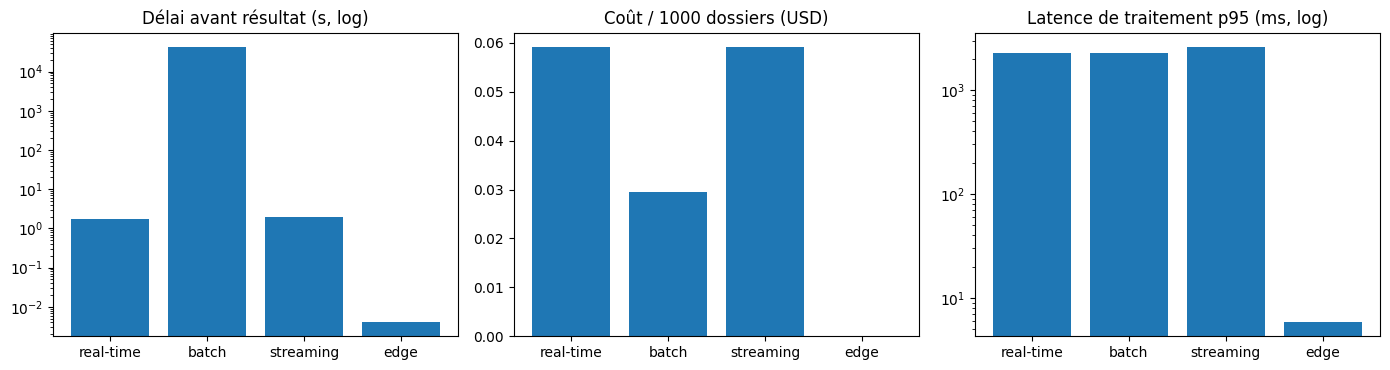

In [4]:
ms = list(resultats)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].bar(ms, [resultats[m]['resume']['delai_resultat_moyen_s'] for m in ms]); ax[0].set_yscale('log'); ax[0].set_title('Délai avant résultat (s, log)')
ax[1].bar(ms, [resultats[m]['resume']['cout_1000_dossiers_usd'] for m in ms]); ax[1].set_title('Coût / 1000 dossiers (USD)')
ax[2].bar(ms, [resultats[m]['resume']['latence_traitement_p95_ms'] for m in ms]); ax[2].set_yscale('log'); ax[2].set_title('Latence de traitement p95 (ms, log)')
plt.tight_layout(); plt.show()

## 4. Robustesse : échec du cloud et repli
Si le LLM échoue après un retry, le dossier part en **revue manuelle** (risque élevé par défaut). L'Edge n'a aucune dépendance réseau.

In [5]:
import copy
avant = dict(PARAMS)
PARAMS['p_echec_cloud'] = 0.30        # panne partielle du fournisseur
_, rt = modes.realtime(dossiers[:500]); _, ed = modes.edge(dossiers[:500])
PARAMS.update(avant)
print('Real-time sous panne : succès', rt['taux_succes_pct'], '%, revue manuelle', rt['revue_manuelle'])
print('Edge sous panne      : succès', ed['taux_succes_pct'], '%, revue manuelle', ed['revue_manuelle'])
assert ed['taux_succes_pct'] == 100

Real-time sous panne : succès 90.4 %, revue manuelle 48
Edge sous panne      : succès 100.0 %, revue manuelle 0


## 5. MLOps vs DevOps : pourquoi DevOps ne suffit pas
Une part croissante de dossiers à risque suit un schéma que les règles ne voient pas (*les habitudes des fraudeurs évoluent*). L'application fonctionne parfaitement (DevOps OK), mais la performance IA chute.

In [6]:
dr = drift.analyser()
pd.DataFrame(dr)

,semaine,part_cas_invisibles,psi_scores,rappel_pct,alerte_psi,alerte_rappel
0,1,0.05,0.0036,94.7,False,False
1,2,0.05,0.0331,95.1,False,False
2,3,0.08,0.0085,92.0,False,False
3,4,0.12,0.0075,88.9,False,False
4,5,0.18,0.0296,84.3,False,True
5,6,0.25,0.0307,79.8,False,True


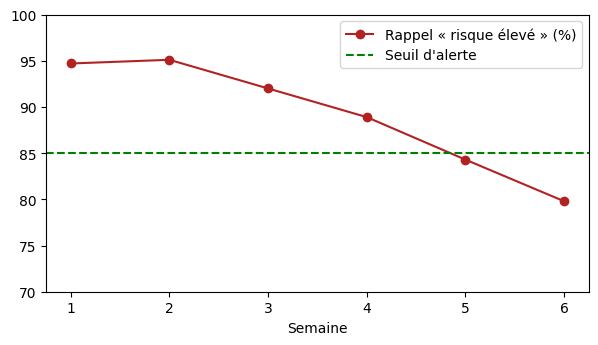

PSI max : 0.0331 (seuil 0.2 ) -> la dérive de performance échappe au seul contrôle des distributions


In [7]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot([x['semaine'] for x in dr], [x['rappel_pct'] for x in dr], 'o-', color='firebrick', label='Rappel « risque élevé » (%)')
ax.axhline(85, ls='--', color='green', label='Seuil d\'alerte'); ax.set_ylim(70, 100); ax.legend(); ax.set_xlabel('Semaine'); plt.show()
print('PSI max :', max(x['psi_scores'] for x in dr), '(seuil', drift.SEUIL_PSI, ') -> la dérive de performance échappe au seul contrôle des distributions')
assert dr[-1]['alerte_rappel'] and not any(x['alerte_psi'] for x in dr)

## 6. Conclusion
- **Batch** : le moins cher, résultat tardif — tâches de fond.
- **Real-time** : réponse immédiate à une requête.
- **Streaming** : flux continu, fort volume.
- **Edge** : confidentialité maximale, hors ligne, mais sans analyse LLM.
- **MLOps** : surveiller la performance IA (pas seulement le système) et recalibrer via le workflow d'approbation.